#  <font color='darkblue'>*Marina Napoleão - EBAC*</font>
## <font color='darkblue'>Projeto de Doenças Cardiovasculares - Regressão Logística</font>

🔹 X = todas as variáveis explicativas (ou preditoras)
  (idade, gênero, altura, peso, colesterol, glicose, etc.)

🔹 Y = variável target, que queremos prever
  (se tem ou não doença cardíaca)

🔹 test_size=0.2 → 20% dos dados serão usados para teste, 80% para treino

🔹 random_state=42 → serve para garantir reprodutibilidade (ou seja, sempre a mesma divisão quando rodar o código novamente)

🔹 O StandardScaler padroniza as variáveis numéricas deixando todas na mesma escala, com:

➔ média = 0

➔ desvio padrão = 1

🔹 Correlação forte (0.80 =< r) | Correlação moderada (0.60 =< r < 0.80) | Correlação fraca (0.40 =< r < 0.60)

# **MÓDULO 27 - Projeto de Doenças Cardiovasculares - Regressão Logística**


Assim como na aula que trabalhamos com uma base de dados nova, com um contexto de modelo de propensão a compra de carros, para a atividade de vocês achei interessante trazer também novos desafios.

Nessa tarefa iremos construir um modelo que nos ajude a prever doenças cardiovasculares, a base contém dados reais.

age - idade dos pacientes

gender - genero (2 mulheres) (1 homens)

height - altura dos pacientes

weight - peso dos pacientes

gluc - glicose

smoke - fumante (1) não fumante (0)

alco - consume alcool (1) não consome (0)

active - realiza atividades fisicas (1) não realiza (0)

cardio_disease - tem doença cardio (1) não tem (0) - Variável target


Seu objetivo é utilizar esses dados históricos dos pacientes e construir um bom modelo de regressão capaz de indicar se novos pacientes estão propensos a doenças cariovasculares ou não.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, classification_report
from sklearn.model_selection import GridSearchCV

# 1) Comece carregando e tratando a base de dados.
Assim como na aula essa nova base não passou por pré processamento nenhum então nessa etapa, carrega os dados, verifique os tipos de dados, verifique se temos dados faltantes e outliers.
Quando necessário realize o tratamento.


In [2]:
base = pd.read_csv("CARDIO_BASE.csv", delimiter=';')

In [3]:
base.head(10)

,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,cardio_disease
0,50,2,168,62,1,1,0,0,1,0
1,55,1,156,85,3,1,0,0,1,1
2,52,1,165,64,3,1,0,0,0,1
3,48,2,169,82,1,1,0,0,1,1
4,48,1,156,56,1,1,0,0,0,0
5,60,1,151,67,2,2,0,0,0,0
6,61,1,157,93,3,1,0,0,1,0
7,62,2,178,95,3,3,0,0,1,1
8,48,1,158,71,1,1,0,0,1,0
9,54,1,164,68,1,1,0,0,0,0


In [4]:
#Verificar os tipos de dados.
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             10000 non-null  int64 
 1   gender          10000 non-null  int64 
 2   height          10000 non-null  int64 
 3   weight          10000 non-null  object
 4   cholesterol     10000 non-null  int64 
 5   gluc            10000 non-null  int64 
 6   smoke           10000 non-null  int64 
 7   alco            10000 non-null  int64 
 8   active          10000 non-null  int64 
 9   cardio_disease  10000 non-null  int64 
dtypes: int64(9), object(1)
memory usage: 781.4+ KB


In [5]:
base['weight'].unique()

array(['62', '85', '64', '82', '56', '67', '93', '95', '71', '68', '80',
       '60', '78', '112', '75', '52', '83', '69', '90', '45', '65', '59',
       '66', '74', '105', '73', '55', '70', '72', '63', '50', '107', '84',
       '77', '79', '76', '58', '115', '97', '53', '57', '49', '110', '94',
       '92', '87', '103', '88', '99', '100', '61', '48', '54', '51', '47',
       '91', '104', '81', '98', '108', '89', '101', '86', '65,5', '142',
       '96', '44', '41', '169', '116', '200', '64,8', '120', '117', '125',
       '106', '114', '113', '129', '124', '42', '123', '111', '102',
       '109', '46', '139', '150', '138', '131', '43', '83,6', '134',
       '106,5', '121', '40', '141', '119', '126', '177', '165', '122',
       '62,3', '118', '89,5', '132', '155', '130', '159', '84,6', '140',
       '82,3', '30', '67,9', '127', '67,5', '74,3', '149', '180', '128',
       '60,2', '64,5', '58,7', '90,5', '37', '80,8', '166', '161', '92,2',
       '75,6', '136', '82,9', '154', '68,9', '170'

In [6]:
base['weight'] = base['weight'].str.replace(',', '.', regex=False)
base['weight'] = base['weight'].astype(float)
base['weight'] = base['weight'].round().astype(int)

In [7]:
#Verificar a distribuição dos dados.
base.describe()

,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,cardio_disease
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,53.288300,1.345400,164.308200,74.303600,1.365000,1.222200,0.089000,0.053700,0.797200,0.503100
std,6.796234,0.475522,8.178796,14.566271,0.677658,0.565561,0.284758,0.225436,0.402105,0.500015
min,30.000000,1.000000,70.000000,30.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,1.000000,159.000000,65.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,165.000000,72.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
75%,58.000000,2.000000,170.000000,82.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,65.000000,2.000000,250.000000,200.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
#Verificar existencia de dados faltantes
verificar_dados_faltantes = base.isnull().values.any()
colunas_dados_faltantes = base.isnull().sum()
percentual_dados_faltantes = (base.isnull().sum() / len(base)) * 100
print('verificando se há dados faltantes:',verificar_dados_faltantes, '\n colunas com dados faltantes: \n', colunas_dados_faltantes, '\n percentual de dados faltantes: \n', percentual_dados_faltantes)

verificando se há dados faltantes: False 
 colunas com dados faltantes: 
 age               0
gender            0
height            0
weight            0
cholesterol       0
gluc              0
smoke             0
alco              0
active            0
cardio_disease    0
dtype: int64 
 percentual de dados faltantes: 
 age               0.0
gender            0.0
height            0.0
weight            0.0
cholesterol       0.0
gluc              0.0
smoke             0.0
alco              0.0
active            0.0
cardio_disease    0.0
dtype: float64


--------

# 2) Agora é hora de explorar os dados com uma análise bem completa.
Plote pelo menos 3 gráficos analisando o comportamento da variável cardio com outras variaveis da sua preferência (análise bivariada). Não se esqueça de trazer insights acerca do analisado.


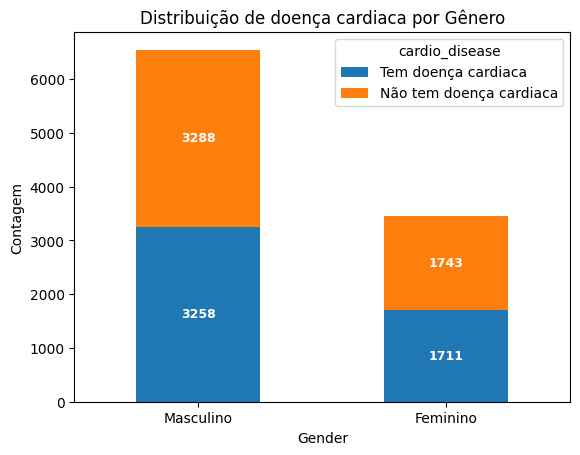

In [9]:
# Gráfico: doença cardíaca por Gênero 
contagem = pd.crosstab(base['gender'], base['cardio_disease'])
ax = contagem.plot(kind='bar', stacked=True)
ax.set_xticklabels(['Masculino', 'Feminino'], rotation=0)
plt.title('Distribuição de doença cardiaca por Gênero')
plt.xlabel('Gender')
plt.ylabel('Contagem')
plt.legend(title='cardio_disease', labels=['Tem doença cardiaca', 'Não tem doença cardiaca'])

for p in ax.patches:
    x = p.get_x() + p.get_width() / 2
    y = p.get_y() + p.get_height() / 2
    value = int(p.get_height())
    
    if value > 0:  # evita escrever em barras vazias
        ax.text(x, y, str(value), ha='center', va='center', fontsize=9, color='white', fontweight='bold')
        
plt.show()

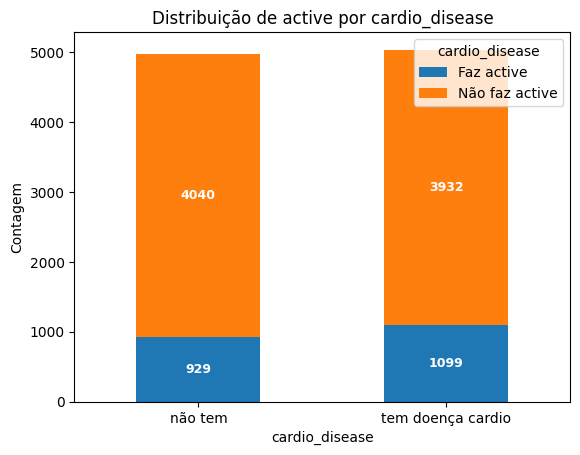

In [10]:
#Gráfico: actividade fisíca por doença cardíaca
contagem = pd.crosstab(base['cardio_disease'], base['active'])
ax = contagem.plot(kind='bar', stacked=True)
ax.set_xticklabels(['não tem', 'tem doença cardio'], rotation=0)
plt.title('Distribuição de active por cardio_disease')
plt.xlabel('cardio_disease')
plt.ylabel('Contagem')
plt.legend(title='cardio_disease', labels=['Faz active', 'Não faz active'])

for p in ax.patches:
    x = p.get_x() + p.get_width() / 2
    y = p.get_y() + p.get_height() / 2
    value = int(p.get_height())
    
    if value > 0:  # evita escrever em barras vazias
        ax.text(x, y, str(value), ha='center', va='center', fontsize=9, color='white', fontweight='bold')
        
plt.show()

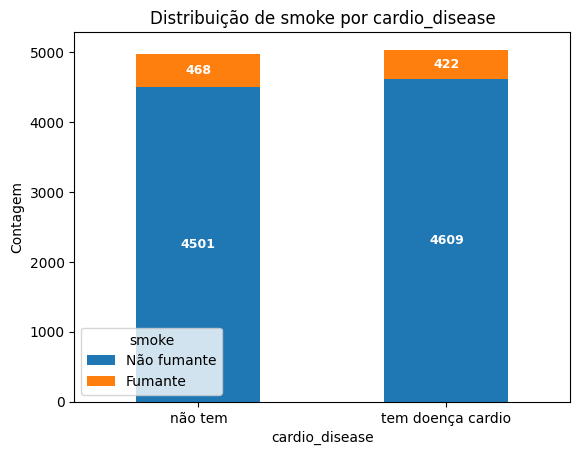

In [11]:
#Gráfico: fumante por doença cardíaca
contagem = pd.crosstab(base['cardio_disease'], base['smoke'])
ax = contagem.plot(kind='bar', stacked=True)
ax.set_xticklabels(['não tem', 'tem doença cardio'], rotation=0)
plt.title('Distribuição de smoke por cardio_disease')
plt.xlabel('cardio_disease')
plt.ylabel('Contagem')
plt.legend(title='smoke', labels=['Não fumante', 'Fumante'])

for p in ax.patches:
    x = p.get_x() + p.get_width() / 2
    y = p.get_y() + p.get_height() / 2
    value = int(p.get_height())
    
    if value > 0:  # evita escrever em barras vazias
        ax.text(x, y, str(value), ha='center', va='center', fontsize=9, color='white', fontweight='bold')
        
plt.show()

In [12]:
media_age = base.groupby('cardio_disease')['age'].mean()
print('0: Não, 1: sim \n \n', media_age)

0: Não, 1: sim 
 
 cardio_disease
0    51.667136
1    54.889485
Name: age, dtype: float64


In [13]:
media_weight = base.groupby('cardio_disease')['weight'].mean()
print('0: Não, 1: sim \n \n', media_weight)

0: Não, 1: sim 
 
 cardio_disease
0    71.616623
1    76.957464
Name: weight, dtype: float64


* <font color='darkblue'>Tanto em homens quanto em mulheres, podemos notar uma quantidade próxima de pessoas saudáveis e pessaoas doentes (doença cardíaca). Todavia, há uma diferença considerável entre os gêneros. Vemos que existem mais homens com doença cardíaca do que mulheres. Isso indica que o gênero pode ter uma média influência no risco de ter doenças cardíacas.</font>


* <font color='darkblue'>Podemos observar que tanto entre os que têm doenças cardíacas quanto os saudaveis há mairoria não pratica atividade física. Porém, vemos uma maior proporção daqueles que praticam atividade entre as pessoas que têm doença cardíaca.</font>


* <font color='darkblue'>Nota-se que o grande percentual das pessoas com ou sem doença cardíaca são não fumantes. E, entre os fumantes, apesar de o número de pessoas saudáveis e com doença cardíaca ser bem próximo, a quantidade é maior nos que têm uma doença cardíaca. O que nos mostra que essa é uma variável com relação positiva com as doenças cardíacas.</font>



---------

# 3) Nessa etapa você deve trazer a matriz de correlação e apontar insights acerca das variáveis com um relacionamento mais forte entre si.



In [14]:
A = base.select_dtypes(include = ['number']).corr()
print(A)

                     age    gender    height    weight  cholesterol      gluc  \
age             1.000000 -0.016550 -0.079205  0.046682     0.172934  0.091026   
gender         -0.016550  1.000000  0.494945  0.149271    -0.032808 -0.025837   
height         -0.079205  0.494945  1.000000  0.290530    -0.044984 -0.024428   
weight          0.046682  0.149271  0.290530  1.000000     0.132096  0.100900   
cholesterol     0.172934 -0.032808 -0.044984  0.132096     1.000000  0.431599   
gluc            0.091026 -0.025837 -0.024428  0.100900     0.431599  1.000000   
smoke          -0.049640  0.332060  0.193053  0.066421     0.024436  0.017538   
alco           -0.043592  0.179608  0.112578  0.079245     0.019636  0.013867   
active         -0.022665  0.011753 -0.010551 -0.020922     0.018799  0.004671   
cardio_disease  0.237076  0.002226 -0.008353  0.183335     0.221273  0.082441   

                   smoke      alco    active  cardio_disease  
age            -0.049640 -0.043592 -0.022665 

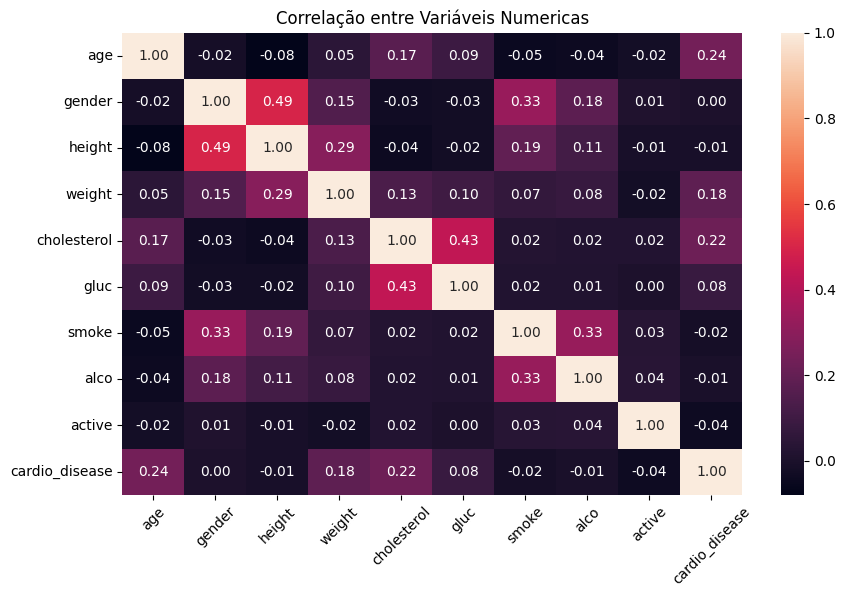

In [15]:
base_corr = base[['age','gender', 'height', 'weight', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio_disease']].corr()
plt.figure(figsize = (10, 6))
sns.heatmap(base_corr, annot = True, fmt = ".2f")
plt.title('Correlação entre Variáveis Numericas')
plt.xticks(rotation=45)
plt.show()

<font color='darkblue'>height e gender correlação positiva: 0.49 → Homens tendem a ter maior altura que mulheres. Esse é um fator biológico já esperado, mas não é importante para o risco de doença.</font>

<font color='darkblue'>cholesterol e gluc correlação positiva: 0.43 → Pessoas com o colesterol alto costumam ter a glicose também alta, indicando um possível risco de doença, sendo então uma correlação importante.</font>

<font color='darkblue'>smoke  e alco correlação positiva: 0.33 → Indica que quem fuma tende a consumir mais álcool, porém não é uma correlação forte o suficiente.</font>

<font color='darkblue'>height e weight correlação positiva: 0.29 → Faz sentido, pois pessoas mais altas costumam pesar mais, todavia não é relevante para o modelo.</font>

-------

# 4) Essa é a sua última etapa pré modelo. Você deve:

### A) Separar a base em treino e teste.

In [16]:
#Verificando balanceamento do dados antes de separar em treino e teste
print('0: Não, 1: sim \n \n', base['cardio_disease'].value_counts())

X = base.drop('cardio_disease', axis=1)  # X contém todas as colunas exceto 'cardio_disease'
Y = base['cardio_disease']  # Y contém apenas a coluna 'cardio_disease'

# Separar em base de treino e teste (usando 80% para treino e 20% para teste)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

0: Não, 1: sim 
 
 cardio_disease
1    5031
0    4969
Name: count, dtype: int64


--------

### B) Você considera que essa base precisa que os dados sejam padronizados? Se sim, porque? Se acredita que devem, então realize essa etapa

In [17]:
# Inicializar StandardScaler
sc = StandardScaler()

# Ajustar e transformar os dados de treino
X_train = sc.fit_transform(X_train)

# Transformar os dados de teste usando os parâmetros aprendidos dos dados de treino
X_test = sc.transform(X_test)

* <font color='darkblue'>age: 30 a 65</font>
* <font color='darkblue'>height: 70 a 250</font>
* <font color='darkblue'>weight: 30 a 200</font>
* <font color='darkblue'>cholesterol e gluc: 1 a 3</font>
* <font color='darkblue'>smoke, alco, active, gender: 0 ou 1 (ou 1 e 2)</font>

<font color='darkblue'>Considero que sim, pois as colunas categóricas age, height e weight têm escalas bem maiores que as colunas numéricas gender, smoke, alco e active. Apesar das colunas numéricas não precisarem ser padronizadas, não há um prejuízo em fazê-las também.</font>

-----------

### C) Verifique se os dados estão balanceados, se não, faça o balanceamento

In [18]:
# Balancear os dados de treinamento usando SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train, Y_train)

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


---------

### D) Visualize as bases de treino, teste (X E Y) e verifique se está tudo adequado.

In [19]:
X_train_balanced

array([[ 0.10037973, -0.73138185, -1.25610705, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-0.19393504,  1.36727483,  0.08809078, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 1.4247962 , -0.73138185, -0.27850863, ..., -0.31328402,
        -0.24037742, -1.96927621],
       ...,
       [ 0.98332404,  1.36727483,  0.65429181, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-1.92199261,  1.36727483,  1.88967284, ...,  3.19199173,
        -0.24037742,  0.50780078],
       [-1.07687935, -0.73138185,  0.84528083, ..., -0.31328402,
        -0.24037742,  0.50780078]])

In [20]:
Y_train_balanced

0       0
1       0
2       1
3       1
4       0
       ..
8059    0
8060    0
8061    0
8062    0
8063    0
Name: cardio_disease, Length: 8064, dtype: int64

In [21]:
X_test

array([[-0.63540719, -0.73138185, -0.03410902, ..., -0.31328402,
        -0.24037742, -1.96927621],
       [ 0.10037973,  1.36727483,  1.43228861, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 0.10037973, -0.73138185, -0.76730784, ..., -0.31328402,
        -0.24037742,  0.50780078],
       ...,
       [-1.66550889, -0.73138185,  0.6990898 , ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-0.48824981, -0.73138185,  0.45469019, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 1.27763881,  1.36727483, -0.03410902, ..., -0.31328402,
        -0.24037742,  0.50780078]])

In [22]:
Y_test

6252    0
4684    0
1731    1
4742    0
4521    1
       ..
6412    1
8285    1
7853    0
1095    1
6929    0
Name: cardio_disease, Length: 2000, dtype: int64

| Conjunto          | Tipo                            | Transformações feitas             | Tamanho aproximado |
| ------------------| --------------------------------| ----------------------------------| -------------------|
| X_train_balanced  | Variáveis explicativas (treino) | Padronizado + Balanceado (SMOTE)  | (8064, 9)          |
| Y_train_balanced  | Target (treino)                 | Balanceado                        | (8064,)            |
| X_test            | Variáveis explicativas (teste)  | Padronizado                       | (2000, 9)          |
| Y_test            | Target (teste)                  | Original                          | (2000,)            |

----------

# 5) Realize a etapa de treinamento do modelo:

### A) Faça o treinamento do modelo.

In [23]:
# seu código aqui
logistic_cardio = LogisticRegression(random_state = 0)

In [24]:
logistic_cardio.fit(X_train_balanced, Y_train_balanced)

LogisticRegression(random_state=0)

----------

### B) Traga o intercept e os coeficientes.

In [25]:
logistic_cardio.intercept_

array([0.0148057])

In [26]:
logistic_cardio.coef_

array([[ 0.44144752,  0.0086153 , -0.07864351,  0.35101781,  0.40818538,
        -0.07356045, -0.0278383 , -0.00871489, -0.07136237]])

In [27]:
coef_base = pd.DataFrame({
    'Variável': X.columns,
    'Coeficiente': logistic_cardio.coef_[0]
}).sort_values(by='Coeficiente', ascending=False)

print(coef_base)

      Variável  Coeficiente
0          age     0.441448
4  cholesterol     0.408185
3       weight     0.351018
1       gender     0.008615
7         alco    -0.008715
6        smoke    -0.027838
8       active    -0.071362
5         gluc    -0.073560
2       height    -0.078644


---------

### c) Avalie as métricas do modelo treinado

* age: 0.44156721 → muito alta <font color='darkblue'>Quanto maior for a idade há mais chances de se ter uma doença cardiaca.</font>
* cholesterol: 0.40808723 →  muito alta <font color='darkblue'>Quanto maior for o colesterol há mais chances de se ter uma doença cardiaca.</font>
* weight: 0.351207 → alta <font color='darkblue'>Peso maior está associado a maior risco de ter doença cardiaca.</font>
* height: -0.078799 → moderada <font color='darkblue'>Pessoas mais altas tendem a ter menor chance de doença.</font>
* active: -0.071316 → leve <font color='darkblue'>Mesmo sendo pouco influente fazer atividade física ajuda a ter menor chance de doença.</font>
* gluc: -0.073642 → quase nulo <font color='darkblue'>Há uma pequena tendencia a glicose mais alta trazer algum risco.</font>
* smoke: -0.027803 → quase nulo <font color='darkblue'>O uso do cigarro tem pouco efeito negativo.</font>
* alco: -0.008611 → quase nulo <font color='darkblue'>O uso de bebidas alcolicas tem pouco efeito negativo.</font>
* gender: 0.008549 → quase nulo <font color='darkblue'>Diferença muito pequena entre homens e mulheres, quase neutro.</font>

----------

### D) Justifique se te parece que o modelo tem feito boas previsões ou não.

<font color='darkblue'>Eu acredito que o modelo tem feito boas previsões, pois ele mostra resultados lógicos e explicáveis, indicando que ele está 'aprendendo' e não apenas 'decorando' os dados. A aplicação do SMOTE fez com que o modelo tivesse mais chance de aprender características de ambas as classes de forma proporcional, assim ajudando a melhorar o recall e presicion.</font>

-------------

# 6) Teste seu modelo!

### A) Aplique o modelo aos dados de teste.

In [28]:
Y_pred_test = logistic_cardio.predict(X_test)

relatorio = classification_report(Y_test, Y_pred_test)

print("Acurácia:", accuracy_score(Y_test, Y_pred_test))
print("\n Matriz de confusão:\n", confusion_matrix(Y_test, Y_pred_test))
print("\n Relatório de Classificação:\n", relatorio)

Acurácia: 0.6585

 Matriz de confusão:
 [[704 297]
 [386 613]]

 Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.65      0.70      0.67      1001
           1       0.67      0.61      0.64       999

    accuracy                           0.66      2000
   macro avg       0.66      0.66      0.66      2000
weighted avg       0.66      0.66      0.66      2000



| Conjunto          | precision | recall | f1-score |
| ------------------| ----------| -------| ---------|
| 0: nao tem        | 0.65      | 0.70   | 0.67     | 
| 1: tem            | 0.67      | 0.61   | 0.64     |

* <font color='darkblue'>Precision 0.67: 67% das pessoas classificadas como doentes realmente têm doença cardíaca.</font>
* <font color='darkblue'>Precision 0.65: 65% das pessoas classificadas como suadáveis realmente não têm doença cardíaca.</font>


* <font color='darkblue'>Recall 0.61: 61% das pessoas classificadas como doentes realmente têm doença cardíaca.</font>
* <font color='darkblue'>Recall 0.70: 70% das pessoas classificadas como saudáveis realmente não têm doença cardíaca.</font>


* <font color='darkblue'>F1-score (0.64 - 0.67): indica uma média equlibrada entre as clases 1 e 0.</font>

----------

### B) Avalie as métricas do modelo treinado

In [29]:
# seu código aqui
previsoes = logistic_cardio.predict(X_train_balanced)

relatorio = classification_report(Y_train_balanced, previsoes)

print("Acurácia:", accuracy_score(Y_train_balanced, previsoes))
print("\n Matriz de confusão:\n", confusion_matrix(Y_train_balanced, previsoes))
print("\n Relatório de Classificação:\n", relatorio)


Acurácia: 0.6350446428571429

 Matriz de confusão:
 [[2670 1362]
 [1581 2451]]

 Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.63      0.66      0.64      4032
           1       0.64      0.61      0.62      4032

    accuracy                           0.64      8064
   macro avg       0.64      0.64      0.63      8064
weighted avg       0.64      0.64      0.63      8064



| Conjunto          | precision | recall | f1-score |
| ------------------| ----------| -------| ---------|
| 0: não tem        | 0.63      | 0.66   | 0.64     |
| 1: tem            | 0.64      | 0.61   | 0.62     | 


* <font color='darkblue'>Precision 0.64: 64% das pessoasclassificadas como doentes realmente têm doença cardíaca.</font>
* <font color='darkblue'>Precision 0.63: 63% das pessoas classificadas como suadáveis realmente não têm doença cardíaca.</font>


* <font color='darkblue'>Recall 0.61: 61% das pessoas classificadas como doentes realmente têm doença cardíaca.</font>
* <font color='darkblue'>Recall 0.66: 66% das pessoas classificadas como saudáveis realmente não têm doença cardíaca.</font>


* <font color='darkblue'>F1-score (0.62 - 0.64): indica uma média equlibrada entre as clases 1 e 0.</font>

------

### C) Plote o gráfico da curva AUC-ROC e explique o que consegue analisar através do gráfico.

In [30]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_test)

# Calcular a AUC
roc_auc = roc_auc_score(Y_test, Y_pred_test)
print("AUC: {:.2f}".format(roc_auc))

AUC: 0.66


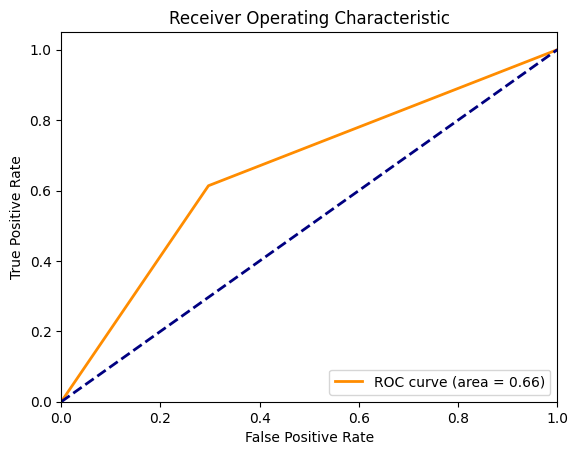

In [31]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

<font color='darkblue'>O eixo X representa o falso positivo e o eixo Y, o verdadeiro positivo. Então, para o modelo, quanto mais perto do eixo Y for a curva, mais eficiente é o modelo. Com uma acurácia de 0.66, sabemos que o modelo acerta 66% das suas previsões. Apesar, de estar mais perto do eixo Y, o modelo tem um desempenho moderado, o que faz sentido devido às métricas de precision, recall e f1-score que apresentavam um equilíbrio razoável.</font>


------------

# 7) Explique:

### A) Explique com suas palavras regressão logistica.

<font color='darkblue'>A regressão logística é um modelo de aprendizado supervisionado utilizado para classificar dados em categorias, como 'sim' ou 'não', usando a função sigmoide para converter variáveis em probabilidades entre 0 e 1.</font>

### B) Explique porque a regressão logistica é um modelo de classificação.

<font color='darkblue'>A regressão logística é considerada um modelo de classificação porque usa a função sigmoide para converter variáveis em probabilidades entre 0 e 1, assim permitindo o ajuste de modelos de classificação binária.</font>

### C) Explique quais pontos em comum a regressão logistica tem da regressão linear.

<font color='darkblue'>A regressão logística e a regressão linear têm em comum o fato de as duas analisarem a relação entre variáveis independentes e uma variável dependente. Ambas estimam coeficientes para cada variável preditoria e usam como base para a previsão uma combinação linear dos valores.</font>

--------

## Hiperparâmetros para Ajuste:

In [32]:
# Criando o modelo de Regressão Logística
logistic_cardio = LogisticRegression(random_state=42, max_iter=10000)

In [33]:
#Especificar os hiperparâmetros e seus valores
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # Parâmetro de regularização
    'penalty': ['l1', 'l2'],  # Tipo de penalidade
    'solver': ['liblinear', 'saga']  # Algoritmo de otimização adequado para L1 e L2
}

In [34]:
# Aplicando o Grid Search com validação cruzada
grid_search = GridSearchCV(logistic_cardio, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_balanced, Y_train_balanced)

GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=10000, random_state=42),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2'],
                         'solver': ['liblinear', 'saga']},
             scoring='accuracy')

In [35]:
# Melhores parâmetros encontrados
best_params_cardio = grid_search.best_params_
print(f"Melhores parâmetros: {best_params_cardio}")

Melhores parâmetros: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}


In [36]:
#Melhor modelo
best_cardio_model = grid_search.best_estimator_

In [37]:
accuracy_train = best_cardio_model.score(X_train_balanced, Y_train_balanced)
print(f"Acurácia do melhor modelo nos dados de treino: {accuracy_train:.4f}")

Acurácia do melhor modelo nos dados de treino: 0.6372


In [38]:
# Fazendo previsões nos dados de treino
Y_pred_cardio = best_cardio_model.predict(X_train_balanced)

# Gerarando o relatório de métricas
report_cardio = classification_report(Y_train_balanced, Y_pred_cardio)
print("Relatório de Métricas - Modelo com Grid Search (Cardio):\n", report_cardio)

Relatório de Métricas - Modelo com Grid Search (Cardio):
               precision    recall  f1-score   support

           0       0.63      0.67      0.65      4032
           1       0.65      0.61      0.63      4032

    accuracy                           0.64      8064
   macro avg       0.64      0.64      0.64      8064
weighted avg       0.64      0.64      0.64      8064



-------

## Implantação e Monitoramento

In [39]:
# Função simples para simular uma previsão nova
def prever_doenca(dados_novos):
    colunas = ['age', 'gender', 'height', 'weight', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']
    dados_df = pd.DataFrame([dados_novos], columns=colunas)
    dados_scaled = sc.transform(dados_df) # aplicar o mesmo scaler usado no treino
    previsao = best_cardio_model.predict(dados_scaled)
    prob = best_cardio_model.predict_proba(dados_scaled)
    print("Probabilidade de ter doença cardíaca:", round(prob[0][1]*100, 2), "%")
    return "Possui doença cardíaca" if previsao[0] == 1 else "Não possui doença cardíaca"

In [40]:
prever_doenca([50, 1, 170, 70, 1, 1, 0, 0, 1])

Probabilidade de ter doença cardíaca: 36.12 %


'Não possui doença cardíaca'